#  This code is to create a heatmap (similar to Mulder et al. 2025 Fig 2G) using the gene signature published datasets and compared it to our DC1 and mreg DC subcluster signatures
Use only the signatures suggested by KR via email on 26.2.26 (looked at those in the file 26.2.26 PublishedDataGee list (KR suggestions) vs DC2 clusters heatmap.ipynb and now looking at the rest of the genes here)
* DC1 - Villani cDC1
* DC1 - Mulder DC1
* Maier mregDC - mregDC
* Moon mreg DC - mreg DC
* Mulder CCR7 DC - mreg DC


In [1]:
#load packages I need
import os
import scanpy as sc
import pandas as pd
#import dandelion as ddl having trouble loading this
from tqdm import tqdm
import matplotlib.pyplot as plt
import scanpy.external as sce
from matplotlib.pyplot import rc_context
import seaborn as sns

In [5]:
import tools

ModuleNotFoundError: No module named 'tools'

In [6]:
from scipy.stats import zscore

In [7]:
import numpy as np

In [8]:
os.getcwd()

'/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code/DEG_Heatmaps'

In [9]:
#show current directory 
os.chdir('/scratch/user/uqlbukat/NRAtlas_analysis_2026')
os.getcwd()

'/scratch/user/uqlbukat/NRAtlas_analysis_2026'

In [10]:
os.listdir()

['20250617_AllDC_bbknn.h5ad',
 'NR_code',
 'PubData_Heatmap.pdf',
 '.ipynb_checkpoints',
 'data_oc.h5ad',
 'NRclean_clustered2.h5ad',
 'alldc_ocdata.RDS',
 '20250629_DC2_bbknn_clustered2.h5ad',
 'figures',
 'Atlas R Analysis',
 'renamed_dc_object.h5ad']

## Import data with the DC1 subclusters

In [11]:
# Import renamed DC anndata
data_DCnew = sc.read_h5ad('/scratch/user/uqlbukat/NRAtlas_analysis_2026/renamed_dc_object.h5ad')

In [12]:
data_DCnew

AnnData object with n_obs × n_vars = 29887 × 1746
    obs: 'nCount_RNA', 'nFeature_RNA', 'sample_type', 'cancer_type', 'patient_id', 'sample_id', 'percent.mt', 'site', 'sample_type_major', 'cancer_subtype', 'integration_id', 'ident', 'dataset_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'S_score', 'G2M_score', 'keep_or_remove', 'leiden', 'celltype', 'leiden_DC', 'leiden_DC_v2', 'exclude_annots', 'leiden_M', 'Technology', 'NR_annotations_simple', 'sample_type_major2', 'cancer_with_H', 'cancer_broadest', 'patient_treatment', 'DC1_sig', 'DC2_sig', 'DC3_sig', 'mregDC_sig', 'NR_cDC2A_Sig', 'NR_cDC2B_Sig', 'NR_DC', 'NR_cDC1 ', 'NR_cDC2', 'NR_cDC3', 'NR_mreg', 'new_subset_heatmap'
    var: 'name', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dr

In [13]:
data_DCnew.obs

,nCount_RNA,nFeature_RNA,sample_type,cancer_type,patient_id,sample_id,percent.mt,site,sample_type_major,cancer_subtype,...,DC3_sig,mregDC_sig,NR_cDC2A_Sig,NR_cDC2B_Sig,NR_DC,NR_cDC1,NR_cDC2,NR_cDC3,NR_mreg,new_subset_heatmap
GSE215120_AM1_AAATGCCCAGAGCCAA-1,17143.000000,2659.000000,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.224990,skin,primary tumour,Acral Melanoma,...,0.462408,0.363655,0.004654,0.915107,1.050759,-0.394701,0.614265,0.201448,0.716073,cDC2B
GSE215120_AM1_ACACTGATCCACTGGG-1,18333.000000,2845.000000,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.063656,skin,primary tumour,Acral Melanoma,...,0.329305,0.540091,0.088663,0.817135,1.002633,-0.192854,0.545078,0.832637,1.339144,cDC2B
GSE215120_AM1_ACAGCCGCAAACCTAC-1,10581.000000,2182.000000,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.050846,skin,primary tumour,Acral Melanoma,...,0.149325,0.032115,0.104029,0.530371,0.512426,-0.399883,-0.269640,-0.425894,0.316475,cDC2B
GSE215120_AM1_ACCAGTAAGACTGGGT-1,8015.000000,1488.000000,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.033687,skin,primary tumour,Acral Melanoma,...,0.004747,0.273282,0.041803,0.678214,0.827228,-0.093832,-0.443113,-0.151862,-0.215953,cDC1
GSE215120_AM1_ACGTCAACAAGGACTG-1,25642.000000,4010.000000,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.835192,skin,primary tumour,Acral Melanoma,...,0.017664,0.119234,0.056861,0.405636,0.113229,-0.179983,-0.543257,-0.592094,-0.284170,cDC1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
GSE180661_HGSOC_SPECTRUM-OV-045_S1_CD45P_LEFT_OVARY_GTTTACTCAAGGCCTC,-9.995153,-8.131683,Adnexa,HGSOC,Left Adnexa,SPECTRUM-OV-045_S1_CD45P_LEFT_OVARY,2694.000000,ovary,primary tumour,HGSOC,...,0.016716,-0.107170,0.152781,0.184119,0.330328,0.842778,-0.603126,-0.343918,-0.422731,cDC1
GSE180661_HGSOC_SPECTRUM-OV-045_S1_CD45P_LEFT_OVARY_TACCGAACAAACCGGA,-9.134331,-8.627023,Adnexa,HGSOC,Left Adnexa,SPECTRUM-OV-045_S1_CD45P_LEFT_OVARY,839.000000,ovary,primary tumour,HGSOC,...,-0.074192,-0.217370,0.399651,-0.341214,0.165999,-0.387327,-0.332132,-0.376656,-0.124059,cDC2
GSE180661_HGSOC_SPECTRUM-OV-045_S1_CD45P_LEFT_OVARY_TCACGCTTCCGTCACT,-10.033317,-7.518040,Adnexa,HGSOC,Left Adnexa,SPECTRUM-OV-045_S1_CD45P_LEFT_OVARY,1683.000000,ovary,primary tumour,HGSOC,...,-0.162280,0.293405,0.001006,0.271965,-3.020549,-0.447874,-0.265839,0.170790,1.057831,mregDC
GSE180661_HGSOC_SPECTRUM-OV-045_S1_CD45P_LEFT_OVARY_TGCAGTAGTGTTGCCG,-9.364501,-8.566583,Adnexa,HGSOC,Left Adnexa,SPECTRUM-OV-045_S1_CD45P_LEFT_OVARY,2257.000000,ovary,primary tumour,HGSOC,...,-0.240000,0.055761,0.708721,-0.228843,-0.187261,-0.580439,-0.314715,0.163491,-0.093947,cDC2


In [14]:
data_DCnew.obs["new_subset_heatmap"]

GSE215120_AM1_AAATGCCCAGAGCCAA-1                                         cDC2B
GSE215120_AM1_ACACTGATCCACTGGG-1                                         cDC2B
GSE215120_AM1_ACAGCCGCAAACCTAC-1                                         cDC2B
GSE215120_AM1_ACCAGTAAGACTGGGT-1                                          cDC1
GSE215120_AM1_ACGTCAACAAGGACTG-1                                          cDC1
                                                                         ...  
GSE180661_HGSOC_SPECTRUM-OV-045_S1_CD45P_LEFT_OVARY_GTTTACTCAAGGCCTC      cDC1
GSE180661_HGSOC_SPECTRUM-OV-045_S1_CD45P_LEFT_OVARY_TACCGAACAAACCGGA      cDC2
GSE180661_HGSOC_SPECTRUM-OV-045_S1_CD45P_LEFT_OVARY_TCACGCTTCCGTCACT    mregDC
GSE180661_HGSOC_SPECTRUM-OV-045_S1_CD45P_LEFT_OVARY_TGCAGTAGTGTTGCCG      cDC2
GSE180661_HGSOC_SPECTRUM-OV-045_S1_CD45P_LEFT_OVARY_TGTGAGTTCGGAAACG    mregDC
Name: new_subset_heatmap, Length: 29887, dtype: category
Categories (5, object): ['cDC1', 'cDC2', 'mregDC', 'cDC2B', 'cDC2A']

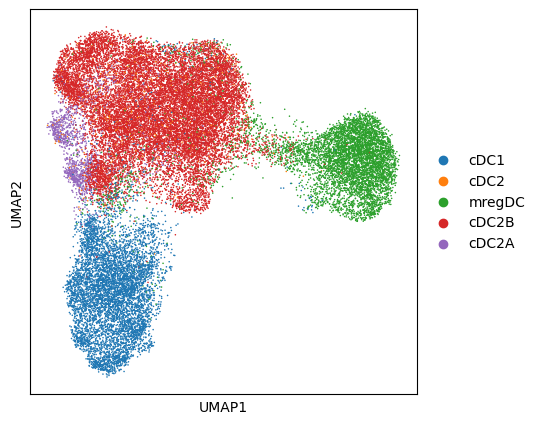

In [15]:
#Visualise data
#export high res umap
with plt.rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(data_DCnew, color=["new_subset_heatmap"], size=5, title="")
#plt.savefig('/scratch/user/uqlbukat/Output/DC2Subcluster_umap.pdf')

   # Save the PDF within the context
#plt.savefig("/scratch/user/uqlbukat/Output/DC2subclusterUmap.pdf", format='pdf')
#plt.close() # Closes to free memory

Isolate the cDC1 and mregDC annotated cell subsets to be used 

In [16]:
data_DCnew.var

,name,mt,n_cells_by_counts,mean_counts,log1p_mean_counts,pct_dropout_by_counts,total_counts,log1p_total_counts,n_cells,highly_variable,means,dispersions,dispersions_norm,mean,std
KLHL17,KLHL17,False,8373,0.013762,0.013668,98.657975,8586.0,9.058005,395,True,0.020695,1.765482,0.770236,4.401962e-16,0.104510
HES4,HES4,False,70336,0.254356,0.226623,88.726543,158695.0,11.974746,3383,True,0.270953,1.909886,1.051629,1.396027e-15,0.398112
ISG15,ISG15,False,353813,6.551920,2.021802,43.290838,4087795.0,15.223517,14721,True,1.347276,3.159896,1.899657,9.448861e-15,0.922907
TNFRSF18,TNFRSF18,False,26091,0.103666,0.098637,95.818133,64678.0,11.077192,1987,True,0.157532,2.008652,1.244088,1.514899e-15,0.300775
TNFRSF4,TNFRSF4,False,33923,0.135501,0.127074,94.562820,84540.0,11.344992,2498,True,0.201545,2.022900,1.271854,1.803994e-15,0.342040
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
S100B,S100B,False,70333,0.709755,0.536350,88.727024,442822.0,13.000925,10344,True,1.835553,3.856184,1.949877,8.585140e-15,1.191227
MT-ATP8,MT-ATP8,True,268154,2.990670,1.383959,57.020266,1865903.0,14.439256,13872,True,1.723030,3.719301,2.726181,2.119527e-14,1.099729
MT-ND4L,MT-ND4L,True,459268,6.269149,1.983639,26.388506,3911372.0,15.179399,22006,True,2.483335,3.879209,2.244271,4.651396e-14,1.282896
MT-ND5,MT-ND5,True,544183,12.252872,2.584214,12.778326,7644665.0,15.849519,26296,True,2.578175,3.077011,0.950360,6.913188e-14,0.828537


## Read in the published gene lists
Looking at only the published genes of interest: DC1 and mreg DC sigs(top 100)

In [17]:
# read in csv file with the Published gene data
gene_list = pd.read_csv("/scratch/user/uqlbukat/gene_sigs_papers_DC1mreg_27.3.26.csv", low_memory = False)

In [18]:
gene_list

,Villani_cDC1,Mulder_DC1,Maier_mregDC,Moon_mregDC,Mulder_CCR7 mDC
0,CLEC9A,CLEC9A,CD40,CCR7,BIRC3
1,C1ORF54,C1orf54,CD80,FSCN1,CCL19
2,HLA-DPA1,SNX3,CD86,CD40,CCR7
3,CADM1,CPNE3,RELB,CD86,CCL22
4,CAMK2D,IRF8,CD83,RELB,FSCN1
...,...,...,...,...,...
95,INF2,MAP2K6,NaN,NaN,CYB5A
96,DUSP2,DPP4,NaN,NaN,TVP23A
97,PALM2,C1orf186,NaN,NaN,SEC61B
98,RAB11FIP4,BIK,NaN,NaN,IL15


In [19]:
gene_list.shape

(100, 5)

In [20]:
type(gene_list)

pandas.core.frame.DataFrame

Remove NAs from the gene_list

In [21]:
# Remove all rows with any NaN values
clean_gene_list = gene_list.dropna()
print("\nDataFrame after dropping rows with any NaN:")
print(clean_gene_list)


DataFrame after dropping rows with any NaN:
   Villani_cDC1 Mulder_DC1 Maier_mregDC Moon_mregDC Mulder_CCR7 mDC
0        CLEC9A     CLEC9A         CD40        CCR7           BIRC3
1       C1ORF54    C1orf54         CD80       FSCN1           CCL19
2      HLA-DPA1       SNX3         CD86        CD40            CCR7
3         CADM1      CPNE3         RELB        CD86           CCL22
4        CAMK2D       IRF8         CD83        RELB           FSCN1
5          CPVL   DNASE1L3        CD274       SOCS2             TXN
6      HLA-DPB2       CPVL     PDCD1LG2       SOCS1        MARCKSL1
7         WDFY4      WDFY4        CD200       IL4I1           LAMP3
8         CPNE3      CADM1          FAS     TNFRSF9            EBI3
9          IDO1      CCND1      ALDH1A2        IDO1            IDO1
10     HLA-DPB1       RGCC        SOCS1       BIRC2          MARCKS
11    LOC645638       NAAA        SOCS2       BIRC3         TNFAIP2
12      HLA-DOB       CST3         CCR7         FAS        TMEM176A
13 

In [22]:
clean_gene_list = gene_list.fillna("")

In [23]:
clean_gene_list.shape

(100, 5)

In [24]:
clean_gene_list

,Villani_cDC1,Mulder_DC1,Maier_mregDC,Moon_mregDC,Mulder_CCR7 mDC
0,CLEC9A,CLEC9A,CD40,CCR7,BIRC3
1,C1ORF54,C1orf54,CD80,FSCN1,CCL19
2,HLA-DPA1,SNX3,CD86,CD40,CCR7
3,CADM1,CPNE3,RELB,CD86,CCL22
4,CAMK2D,IRF8,CD83,RELB,FSCN1
...,...,...,...,...,...
95,INF2,MAP2K6,,,CYB5A
96,DUSP2,DPP4,,,TVP23A
97,PALM2,C1orf186,,,SEC61B
98,RAB11FIP4,BIK,,,IL15


In [25]:
## Create a data frame with all the gene lists in one
gene_df = gene_list.apply(lambda s: s.dropna().tolist()).to_frame().T
# gene_df.columns are your original columns
# gene_df.loc[0, "Column 1"] == ["gene 1", "gene 2"]

In [26]:
gene_df

,Villani_cDC1,Mulder_DC1,Maier_mregDC,Moon_mregDC,Mulder_CCR7 mDC
0,"[CLEC9A, C1ORF54, HLA-DPA1, CADM1, CAMK2D, CPV...","[CLEC9A, C1orf54, SNX3, CPNE3, IRF8, DNASE1L3,...","[CD40, CD80, CD86, RELB, CD83, CD274, PDCD1LG2...","[CCR7, FSCN1, CD40, CD86, RELB, SOCS2, SOCS1, ...","[BIRC3, CCL19, CCR7, CCL22, FSCN1, TXN, MARCKS..."


In [27]:
type (gene_df)

pandas.core.frame.DataFrame

## Create a heatmap with the gene lists and the DC data

In [28]:
gene_dict = gene_df.iloc[0].to_dict()
# keys: column names, values: lists of genes

In [29]:
gene_dict

{'Villani_cDC1': ['CLEC9A',
  'C1ORF54',
  'HLA-DPA1',
  'CADM1',
  'CAMK2D',
  'CPVL',
  'HLA-DPB2',
  'WDFY4',
  'CPNE3',
  'IDO1',
  'HLA-DPB1',
  'LOC645638',
  'HLA-DOB',
  'HLA-DQB1',
  'HLA-DQB',
  'CLNK',
  'CSRP1',
  'SNX3',
  'ZNF366',
  'KIAA1598',
  'NDRG2',
  'ENPP1',
  'RGS10',
  'AX747832',
  'CYB5R3',
  'ID2',
  'XCR1',
  'FAM190A',
  'ASAP1',
  'SLAMF8',
  'CD59',
  'DHRS3',
  'GCET2',
  'FNBP1',
  'TMEM14A',
  'NET1',
  'BTLA',
  'BCL6',
  'FLT3',
  'ADAM28',
  'SLAMF7',
  'BATF3',
  'LGALS2',
  'VAC14',
  'PPA1',
  'APOL3',
  'C1ORF21',
  'CCND1',
  'ANPEP',
  'ELOVL5',
  'NCALD',
  'ACTN1',
  'PIK3CB',
  'HAVCR2',
  'GYPC',
  'TLR10',
  'ASB2',
  'KIF16B',
  'LRRC18',
  'DST',
  'DENND1B',
  'DNASE1L3',
  'SLC24A4',
  'VAV3',
  'THBD',
  'NAV1',
  'GSTM4',
  'TRERF1',
  'B3GNT7',
  'LACC1',
  'LMNA',
  'PTK2',
  'IDO2',
  'MTERFD3',
  'CD93',
  'DPP4',
  'SLC9A9',
  'FCRL6',
  'PDLIM7',
  'CYP2E1',
  'PDE4DIP',
  'LIMA1',
  'CTTNBP2NL',
  'PPM1M',
  'OSBPL3',
  'PLC

In [31]:
# Loop through each gene set and calculate the scores
for name, genes in gene_dict.items():
    sc.tl.score_genes(data_DCnew, genes, score_name=name)

       'FAM190A', 'GCET2', 'C1ORF21', 'LRRC18', 'MTERFD3', 'LOC541471',
       'PALM2'],
      dtype='object')


In [32]:
data_DCnew.obs.head()

,nCount_RNA,nFeature_RNA,sample_type,cancer_type,patient_id,sample_id,percent.mt,site,sample_type_major,cancer_subtype,...,NR_cDC1,NR_cDC2,NR_cDC3,NR_mreg,new_subset_heatmap,Villani_cDC1,Mulder_DC1,Maier_mregDC,Moon_mregDC,Mulder_CCR7 mDC
GSE215120_AM1_AAATGCCCAGAGCCAA-1,17143.0,2659.0,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.224990,skin,primary tumour,Acral Melanoma,...,-0.394701,0.614265,0.201448,0.716073,cDC2B,0.156296,0.337836,0.363655,0.474075,0.414209
GSE215120_AM1_ACACTGATCCACTGGG-1,18333.0,2845.0,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.063656,skin,primary tumour,Acral Melanoma,...,-0.192854,0.545078,0.832637,1.339144,cDC2B,0.186305,0.370308,0.540091,0.674157,0.552408
GSE215120_AM1_ACAGCCGCAAACCTAC-1,10581.0,2182.0,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.050846,skin,primary tumour,Acral Melanoma,...,-0.399883,-0.269640,-0.425894,0.316475,cDC2B,0.130907,0.379482,0.032115,0.220550,0.264942
GSE215120_AM1_ACCAGTAAGACTGGGT-1,8015.0,1488.0,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.033687,skin,primary tumour,Acral Melanoma,...,-0.093832,-0.443113,-0.151862,-0.215953,cDC1,0.364139,0.761479,0.273282,0.308535,0.364825
GSE215120_AM1_ACGTCAACAAGGACTG-1,25642.0,4010.0,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.835192,skin,primary tumour,Acral Melanoma,...,-0.179983,-0.543257,-0.592094,-0.284170,cDC1,0.367768,0.774956,0.119234,0.100924,0.180404


## Check the structure of the data

In [33]:
data_DCnew.obs_names.is_unique

True

In [34]:
data_DCnew.obs_names[:5]

Index(['GSE215120_AM1_AAATGCCCAGAGCCAA-1', 'GSE215120_AM1_ACACTGATCCACTGGG-1',
       'GSE215120_AM1_ACAGCCGCAAACCTAC-1', 'GSE215120_AM1_ACCAGTAAGACTGGGT-1',
       'GSE215120_AM1_ACGTCAACAAGGACTG-1'],
      dtype='object')

In [35]:
data_DCnew.obs.shape

(29887, 56)

# Creating z-score heatmap using average gene expression

In [48]:
#Identify our cell subsets of interest
cell_subsets = ['cDC1', 'cDC2', 'mregDC', 'cDC2B', 'cDC2A']

In [55]:
#Published gene lists as a Python dict {signature_name: [genes]}
signatures = gene_dict
signatures

{'Villani_cDC1': ['CLEC9A',
  'C1ORF54',
  'HLA-DPA1',
  'CADM1',
  'CAMK2D',
  'CPVL',
  'HLA-DPB2',
  'WDFY4',
  'CPNE3',
  'IDO1',
  'HLA-DPB1',
  'LOC645638',
  'HLA-DOB',
  'HLA-DQB1',
  'HLA-DQB',
  'CLNK',
  'CSRP1',
  'SNX3',
  'ZNF366',
  'KIAA1598',
  'NDRG2',
  'ENPP1',
  'RGS10',
  'AX747832',
  'CYB5R3',
  'ID2',
  'XCR1',
  'FAM190A',
  'ASAP1',
  'SLAMF8',
  'CD59',
  'DHRS3',
  'GCET2',
  'FNBP1',
  'TMEM14A',
  'NET1',
  'BTLA',
  'BCL6',
  'FLT3',
  'ADAM28',
  'SLAMF7',
  'BATF3',
  'LGALS2',
  'VAC14',
  'PPA1',
  'APOL3',
  'C1ORF21',
  'CCND1',
  'ANPEP',
  'ELOVL5',
  'NCALD',
  'ACTN1',
  'PIK3CB',
  'HAVCR2',
  'GYPC',
  'TLR10',
  'ASB2',
  'KIF16B',
  'LRRC18',
  'DST',
  'DENND1B',
  'DNASE1L3',
  'SLC24A4',
  'VAV3',
  'THBD',
  'NAV1',
  'GSTM4',
  'TRERF1',
  'B3GNT7',
  'LACC1',
  'LMNA',
  'PTK2',
  'IDO2',
  'MTERFD3',
  'CD93',
  'DPP4',
  'SLC9A9',
  'FCRL6',
  'PDLIM7',
  'CYP2E1',
  'PDE4DIP',
  'LIMA1',
  'CTTNBP2NL',
  'PPM1M',
  'OSBPL3',
  'PLC

In [44]:
data_DCnew.var_names

Index(['KLHL17', 'HES4', 'ISG15', 'TNFRSF18', 'TNFRSF4', 'MORN1', 'ACOT7',
       'ERRFI1', 'SLC2A5', 'GPR157',
       ...
       'COL18A1', 'PCBP3', 'COL6A1', 'COL6A2', 'DIP2A', 'S100B', 'MT-ATP8',
       'MT-ND4L', 'MT-ND5', 'MT-ND6'],
      dtype='object', length=1746)

## Compute average expression per cell subset

In [45]:
# Make a DataFrame of expression: genes x cells
# If X is sparse, toarray() is OK for moderate size; else keep sparse ops
expr = data_DCnew.to_df()  # shape: (n_cells, n_genes)
expr.index = data_DCnew.obs_names
expr.columns = data_DCnew.var_names

In [46]:
# Add subset labels
meta = data_DCnew.obs.copy()
meta["cell_id"] = meta.index

In [47]:
meta

,nCount_RNA,nFeature_RNA,sample_type,cancer_type,patient_id,sample_id,percent.mt,site,sample_type_major,cancer_subtype,...,NR_cDC2,NR_cDC3,NR_mreg,new_subset_heatmap,Villani_cDC1,Mulder_DC1,Maier_mregDC,Moon_mregDC,Mulder_CCR7 mDC,cell_id
GSE215120_AM1_AAATGCCCAGAGCCAA-1,17143.000000,2659.000000,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.224990,skin,primary tumour,Acral Melanoma,...,0.614265,0.201448,0.716073,cDC2B,0.156296,0.337836,0.363655,0.474075,0.414209,GSE215120_AM1_AAATGCCCAGAGCCAA-1
GSE215120_AM1_ACACTGATCCACTGGG-1,18333.000000,2845.000000,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.063656,skin,primary tumour,Acral Melanoma,...,0.545078,0.832637,1.339144,cDC2B,0.186305,0.370308,0.540091,0.674157,0.552408,GSE215120_AM1_ACACTGATCCACTGGG-1
GSE215120_AM1_ACAGCCGCAAACCTAC-1,10581.000000,2182.000000,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.050846,skin,primary tumour,Acral Melanoma,...,-0.269640,-0.425894,0.316475,cDC2B,0.130907,0.379482,0.032115,0.220550,0.264942,GSE215120_AM1_ACAGCCGCAAACCTAC-1
GSE215120_AM1_ACCAGTAAGACTGGGT-1,8015.000000,1488.000000,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.033687,skin,primary tumour,Acral Melanoma,...,-0.443113,-0.151862,-0.215953,cDC1,0.364139,0.761479,0.273282,0.308535,0.364825,GSE215120_AM1_ACCAGTAAGACTGGGT-1
GSE215120_AM1_ACGTCAACAAGGACTG-1,25642.000000,4010.000000,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.835192,skin,primary tumour,Acral Melanoma,...,-0.543257,-0.592094,-0.284170,cDC1,0.367768,0.774956,0.119234,0.100924,0.180404,GSE215120_AM1_ACGTCAACAAGGACTG-1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
GSE180661_HGSOC_SPECTRUM-OV-045_S1_CD45P_LEFT_OVARY_GTTTACTCAAGGCCTC,-9.995153,-8.131683,Adnexa,HGSOC,Left Adnexa,SPECTRUM-OV-045_S1_CD45P_LEFT_OVARY,2694.000000,ovary,primary tumour,HGSOC,...,-0.603126,-0.343918,-0.422731,cDC1,0.795491,1.011710,-0.107170,0.228415,0.205365,GSE180661_HGSOC_SPECTRUM-OV-045_S1_CD45P_LEFT_...
GSE180661_HGSOC_SPECTRUM-OV-045_S1_CD45P_LEFT_OVARY_TACCGAACAAACCGGA,-9.134331,-8.627023,Adnexa,HGSOC,Left Adnexa,SPECTRUM-OV-045_S1_CD45P_LEFT_OVARY,839.000000,ovary,primary tumour,HGSOC,...,-0.332132,-0.376656,-0.124059,cDC2,0.115569,0.395104,-0.217370,-0.042696,0.030284,GSE180661_HGSOC_SPECTRUM-OV-045_S1_CD45P_LEFT_...
GSE180661_HGSOC_SPECTRUM-OV-045_S1_CD45P_LEFT_OVARY_TCACGCTTCCGTCACT,-10.033317,-7.518040,Adnexa,HGSOC,Left Adnexa,SPECTRUM-OV-045_S1_CD45P_LEFT_OVARY,1683.000000,ovary,primary tumour,HGSOC,...,-0.265839,0.170790,1.057831,mregDC,0.004839,0.116642,0.293405,0.718732,1.040020,GSE180661_HGSOC_SPECTRUM-OV-045_S1_CD45P_LEFT_...
GSE180661_HGSOC_SPECTRUM-OV-045_S1_CD45P_LEFT_OVARY_TGCAGTAGTGTTGCCG,-9.364501,-8.566583,Adnexa,HGSOC,Left Adnexa,SPECTRUM-OV-045_S1_CD45P_LEFT_OVARY,2257.000000,ovary,primary tumour,HGSOC,...,-0.314715,0.163491,-0.093947,cDC2,0.002136,0.192854,0.055761,0.155128,0.290231,GSE180661_HGSOC_SPECTRUM-OV-045_S1_CD45P_LEFT_...


In [49]:
# Restrict to relevant subsets
keep_cells = meta["new_subset_heatmap"].isin(cell_subsets)
expr_sub = expr.loc[keep_cells, :]
meta_sub = meta.loc[keep_cells, :]

In [50]:
# Compute mean expression per gene per subset
# groupby on new_subset_heatmap
expr_sub["new_subset_heatmap"] = meta_sub["new_subset_heatmap"].values
mean_expr_by_subset = (
    expr_sub.groupby("new_subset_heatmap")
    .mean()
    .T  # now: genes x subsets
)
mean_expr_by_subset

/scratch/temp/22829923/ipykernel_4034153/3079306782.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  expr_sub.groupby("new_subset_heatmap")


new_subset_heatmap,cDC1,cDC2,mregDC,cDC2B,cDC2A
KLHL17,-0.023827,-0.009356,0.081015,-0.042245,-0.029646
HES4,-0.218998,0.097662,0.083915,0.066381,-0.096598
ISG15,0.057994,0.283471,-0.118979,0.014296,-0.028327
TNFRSF18,-0.115884,0.032223,0.163831,-0.007598,-0.108084
TNFRSF4,-0.165646,-0.041294,0.344123,-0.047257,-0.185803
...,...,...,...,...,...
S100B,0.433102,-0.123839,-0.312065,-0.202761,1.756138
MT-ATP8,-0.030203,-0.102356,0.029075,0.011149,-0.074393
MT-ND4L,-0.042335,-0.130958,0.098137,-0.014010,-0.021872
MT-ND5,-0.249794,0.034465,-0.044811,0.155730,-0.384481


In [56]:
signatures

{'Villani_cDC1': ['CLEC9A',
  'C1ORF54',
  'HLA-DPA1',
  'CADM1',
  'CAMK2D',
  'CPVL',
  'HLA-DPB2',
  'WDFY4',
  'CPNE3',
  'IDO1',
  'HLA-DPB1',
  'LOC645638',
  'HLA-DOB',
  'HLA-DQB1',
  'HLA-DQB',
  'CLNK',
  'CSRP1',
  'SNX3',
  'ZNF366',
  'KIAA1598',
  'NDRG2',
  'ENPP1',
  'RGS10',
  'AX747832',
  'CYB5R3',
  'ID2',
  'XCR1',
  'FAM190A',
  'ASAP1',
  'SLAMF8',
  'CD59',
  'DHRS3',
  'GCET2',
  'FNBP1',
  'TMEM14A',
  'NET1',
  'BTLA',
  'BCL6',
  'FLT3',
  'ADAM28',
  'SLAMF7',
  'BATF3',
  'LGALS2',
  'VAC14',
  'PPA1',
  'APOL3',
  'C1ORF21',
  'CCND1',
  'ANPEP',
  'ELOVL5',
  'NCALD',
  'ACTN1',
  'PIK3CB',
  'HAVCR2',
  'GYPC',
  'TLR10',
  'ASB2',
  'KIF16B',
  'LRRC18',
  'DST',
  'DENND1B',
  'DNASE1L3',
  'SLC24A4',
  'VAV3',
  'THBD',
  'NAV1',
  'GSTM4',
  'TRERF1',
  'B3GNT7',
  'LACC1',
  'LMNA',
  'PTK2',
  'IDO2',
  'MTERFD3',
  'CD93',
  'DPP4',
  'SLC9A9',
  'FCRL6',
  'PDLIM7',
  'CYP2E1',
  'PDE4DIP',
  'LIMA1',
  'CTTNBP2NL',
  'PPM1M',
  'OSBPL3',
  'PLC

In [57]:
#Collapse to signature scores (mean expression of each gene list)

#Create matrix: rows = cell subsets, cols = signatures
subset_names = cell_subsets
sig_names = list(signatures.keys())
sig_names

['Villani_cDC1',
 'Mulder_DC1',
 'Maier_mregDC',
 'Moon_mregDC',
 'Mulder_CCR7 mDC']

In [58]:
subset_names

['cDC1', 'cDC2', 'mregDC', 'cDC2B', 'cDC2A']

In [59]:
sig_mat = pd.DataFrame(
    index=subset_names,
    columns=sig_names,
    dtype=float
)

In [60]:
#Create empty matrix of signatures
sig_mat

,Villani_cDC1,Mulder_DC1,Maier_mregDC,Moon_mregDC,Mulder_CCR7 mDC
cDC1,NaN,NaN,NaN,NaN,NaN
cDC2,NaN,NaN,NaN,NaN,NaN
mregDC,NaN,NaN,NaN,NaN,NaN
cDC2B,NaN,NaN,NaN,NaN,NaN
cDC2A,NaN,NaN,NaN,NaN,NaN


In [61]:
#populate signature matrix
for sig_name, genes in signatures.items():
    # Intersect with genes present in the object
    genes_in_data = list(set(genes).intersection(mean_expr_by_subset.index))
    if len(genes_in_data) == 0:
        print(f"No genes from {sig_name} found in data; skipping.")
        continue
    
    # mean expression of this signature per subset
    # mean_expr_by_subset: genes x subsets
    sig_values = mean_expr_by_subset.loc[genes_in_data].mean(axis=0)
    
    # Fill into sig_mat
    sig_mat.loc[:, sig_name] = sig_values.loc[subset_names].values

In [62]:
sig_mat

,Villani_cDC1,Mulder_DC1,Maier_mregDC,Moon_mregDC,Mulder_CCR7 mDC
cDC1,0.721116,0.966634,-0.227233,-0.172194,-0.239191
cDC2,-0.201909,-0.282034,-0.146705,-0.190344,-0.220322
mregDC,-0.189777,-0.233405,0.754801,0.823551,0.942638
cDC2B,-0.211884,-0.300055,-0.173231,-0.218913,-0.235492
cDC2A,-0.239512,-0.214748,-0.269052,-0.294917,-0.294974


## Z-score and plot heatmap in Python (pheatmap-style)

In [63]:
# Drop any all-NaN columns, if any signatures were skipped
sig_mat_clean = sig_mat.dropna(axis=1, how="all")
sig_mat_clean

,Villani_cDC1,Mulder_DC1,Maier_mregDC,Moon_mregDC,Mulder_CCR7 mDC
cDC1,0.721116,0.966634,-0.227233,-0.172194,-0.239191
cDC2,-0.201909,-0.282034,-0.146705,-0.190344,-0.220322
mregDC,-0.189777,-0.233405,0.754801,0.823551,0.942638
cDC2B,-0.211884,-0.300055,-0.173231,-0.218913,-0.235492
cDC2A,-0.239512,-0.214748,-0.269052,-0.294917,-0.294974


In [64]:
# Z-score across subsets for each signature (so you compare cell types per signature)
# axis=0 => z-score down rows; we want per column, so axis=0 with .apply on DataFrame
sig_z = sig_mat_clean.apply(zscore, axis=0, result_type="broadcast")

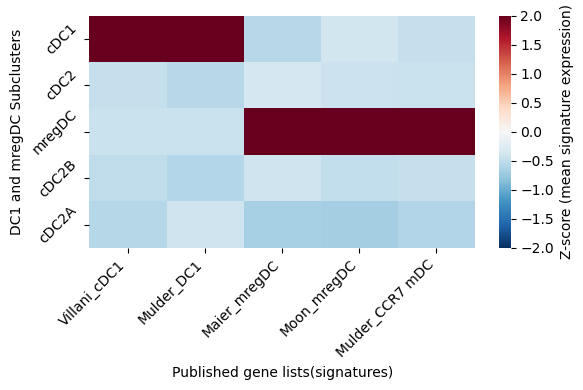

In [65]:
plt.figure(figsize=(len(sig_z.columns) * 0.4 + 4, len(sig_z.index) * 0.4 + 2))
sns.heatmap(
    sig_z,
    cmap="RdBu_r",
    center=0,
    vmin=-2,
    vmax=2,
    xticklabels=True,
    yticklabels=True,
    cbar_kws={"label": "Z-score (mean signature expression)"}
)
plt.xlabel("Published gene lists(signatures)")
plt.ylabel("DC1 and mregDC Subclusters")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=45)
plt.tight_layout()
# Save the plot as a PDF file
plt.savefig('/scratch/user/uqlbukat/Output/PubData_DC1mregonly27326_Heatmap.pdf')
plt.show()

## Overlay Published signatures on our DC1 and mregDC atlas to see where the cells sit

Visualise the clusters in a UMAP

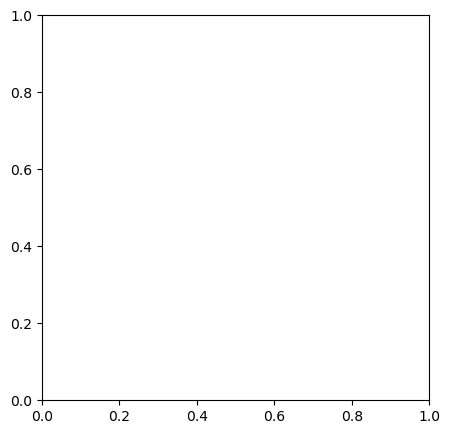

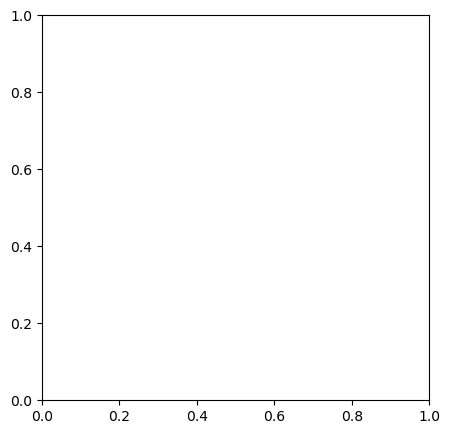

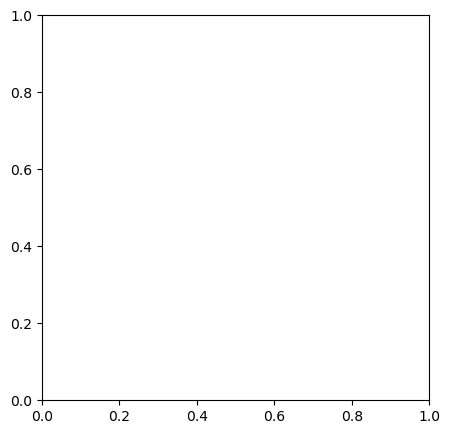

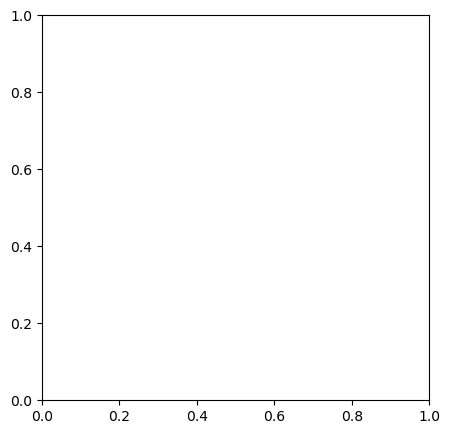

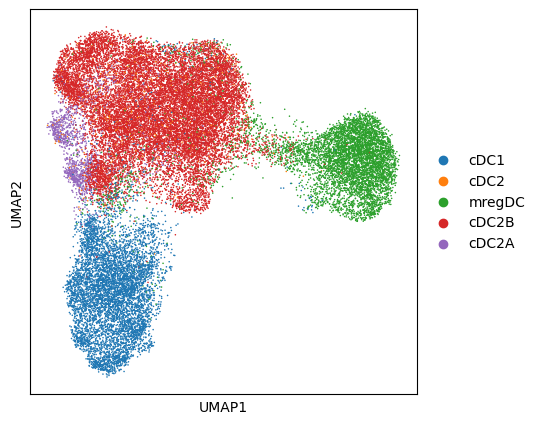

In [70]:
#export high res umap
with plt.rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(data_DCnew, color=["new_subset_heatmap"], size=5, title="")
#plt.savefig('/scratch/user/uqlbukat/Output/DC2Subcluster_umap.pdf')

   # Save the PDF within the context
plt.savefig("/scratch/user/uqlbukat/Output/newDC_Umap.pdf", format='pdf')
plt.close() # Closes to free memory

Now visualise the expression of the signatures on the UMAP

In [71]:
gene_dict

{'Villani_cDC1': ['CLEC9A',
  'C1ORF54',
  'HLA-DPA1',
  'CADM1',
  'CAMK2D',
  'CPVL',
  'HLA-DPB2',
  'WDFY4',
  'CPNE3',
  'IDO1',
  'HLA-DPB1',
  'LOC645638',
  'HLA-DOB',
  'HLA-DQB1',
  'HLA-DQB',
  'CLNK',
  'CSRP1',
  'SNX3',
  'ZNF366',
  'KIAA1598',
  'NDRG2',
  'ENPP1',
  'RGS10',
  'AX747832',
  'CYB5R3',
  'ID2',
  'XCR1',
  'FAM190A',
  'ASAP1',
  'SLAMF8',
  'CD59',
  'DHRS3',
  'GCET2',
  'FNBP1',
  'TMEM14A',
  'NET1',
  'BTLA',
  'BCL6',
  'FLT3',
  'ADAM28',
  'SLAMF7',
  'BATF3',
  'LGALS2',
  'VAC14',
  'PPA1',
  'APOL3',
  'C1ORF21',
  'CCND1',
  'ANPEP',
  'ELOVL5',
  'NCALD',
  'ACTN1',
  'PIK3CB',
  'HAVCR2',
  'GYPC',
  'TLR10',
  'ASB2',
  'KIF16B',
  'LRRC18',
  'DST',
  'DENND1B',
  'DNASE1L3',
  'SLC24A4',
  'VAV3',
  'THBD',
  'NAV1',
  'GSTM4',
  'TRERF1',
  'B3GNT7',
  'LACC1',
  'LMNA',
  'PTK2',
  'IDO2',
  'MTERFD3',
  'CD93',
  'DPP4',
  'SLC9A9',
  'FCRL6',
  'PDLIM7',
  'CYP2E1',
  'PDE4DIP',
  'LIMA1',
  'CTTNBP2NL',
  'PPM1M',
  'OSBPL3',
  'PLC

In [72]:
#mask data and use to calculate gene scores
adata_DCnew = data_DCnew

In [73]:
adata_DCnew

AnnData object with n_obs × n_vars = 29887 × 1746
    obs: 'nCount_RNA', 'nFeature_RNA', 'sample_type', 'cancer_type', 'patient_id', 'sample_id', 'percent.mt', 'site', 'sample_type_major', 'cancer_subtype', 'integration_id', 'ident', 'dataset_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'S_score', 'G2M_score', 'keep_or_remove', 'leiden', 'celltype', 'leiden_DC', 'leiden_DC_v2', 'exclude_annots', 'leiden_M', 'Technology', 'NR_annotations_simple', 'sample_type_major2', 'cancer_with_H', 'cancer_broadest', 'patient_treatment', 'DC1_sig', 'DC2_sig', 'DC3_sig', 'mregDC_sig', 'NR_cDC2A_Sig', 'NR_cDC2B_Sig', 'NR_DC', 'NR_cDC1 ', 'NR_cDC2', 'NR_cDC3', 'NR_mreg', 'new_subset_heatmap', 'Villani_cDC1', 'Mulder_DC1', 'Maier_mregDC', 'Moon_mregDC', 'Mulder_CCR7 mDC'
    var

In [74]:
# Loop through each gene set and calculate the scores
for name, genes in gene_dict.items():
    sc.tl.score_genes(adata_DCnew, genes, score_name=name)

       'FAM190A', 'GCET2', 'C1ORF21', 'LRRC18', 'MTERFD3', 'LOC541471',
       'PALM2'],
      dtype='object')


In [75]:
colour_vars = gene_dict

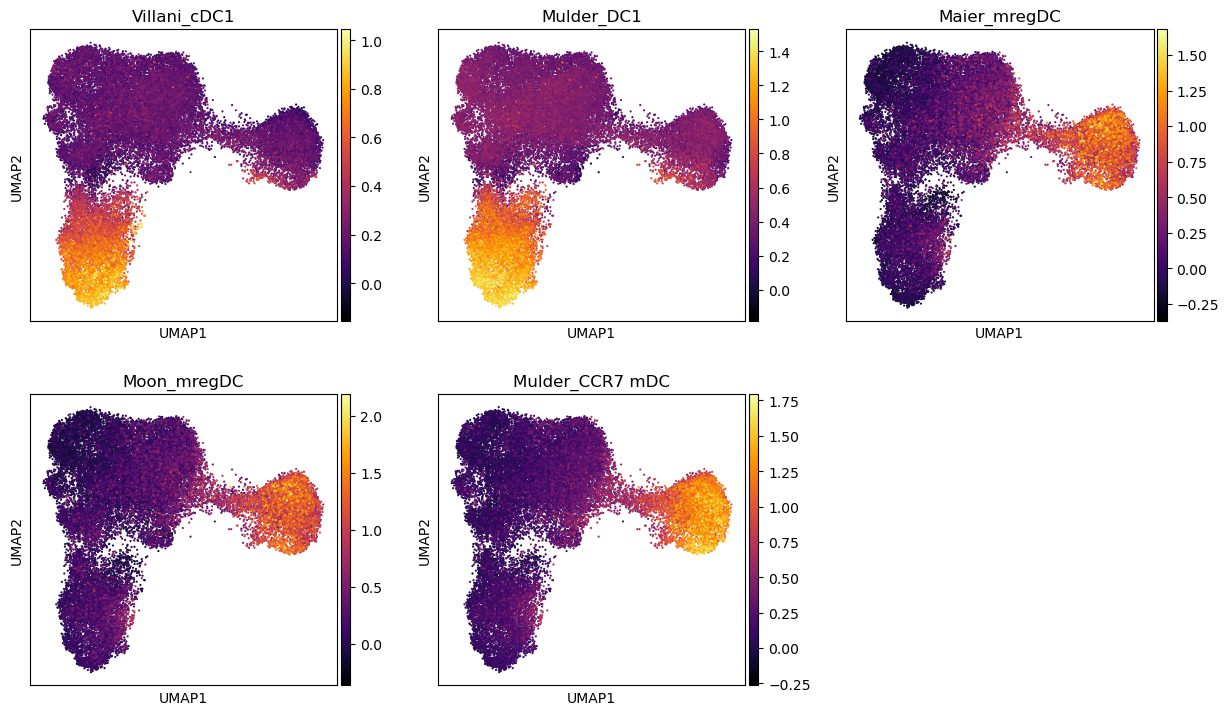

In [76]:
#plotting 
with plt.rc_context({"figure.figsize": (4, 4)}):
    sc.pl.umap(adata_DCnew, color=colour_vars, ncols=3, size=10,
                cmap='inferno')
#plt.savefig('/scratch/user/uqlbukat/Output/PublishedSigs_DC2SubclusterOverlay.pdf')